# 1.04 — Integración del target: salidas por estación y hora

**Proyecto:** MiBici — TC5044.10 — Equipo 04
**Autor:** Leonardo Santos García
**Fecha:** 24 de octubre de 2026
**Rama:** `feat/pr2-integration`

> **Problema de negocio:** Pronosticar viajes iniciados por estación y por hora para el día siguiente, con el objetivo de apoyar la planeación del rebalanceo de bicicletas.

Este notebook **no construye datos**: lee las salidas del pipeline (`make interim`, `make station-hour`), las valida visualmente, integra el EDA del equipo y documenta las decisiones que dan forma a `processed_v1`. La lógica vive en `mibici/` y está probada en `tests/`.

## 1. Objetivo

1. Verificar que la base `station_hour_base` representa correctamente el target: una fila por estación y hora **activa**, con ceros solo donde la estación existía.
2. Integrar los hallazgos de los notebooks de EDA del equipo (1.01, 1.02, 1.03).
3. Tomar y justificar las decisiones abiertas (contrato de predicción, periodo, flags, estaciones nuevas, días atípicos).
4. Documentar `processed_v1` y su registro en MLflow.

### 1.1 Formulación del problema

Es un problema de **aprendizaje supervisado de conteos sobre series de tiempo** (una serie por estación):

$$y_{s,t} \in \mathbb{N}_0 = \{0, 1, 2, \dots\}$$

- $y_{s,t}$: número de viajes que **inician** en la estación $s$ durante la hora $t$ (target, columna `departures`).
- $s \in \{1, \dots, S\}$: estación activa en la hora $t$ ($S = 486$ estaciones con viajes en el histórico).
- $t$: intervalo de una hora, `[hour_start, hour_start + 1 h)`.
- $y_{s,t}$ solo está definido cuando la estación $s$ opera en la hora $t$; fuera de su ventana activa no existe observación (no es 0).

**Contrato de predicción (por definir con evidencia, sección 3.3):** para cada día $d$, con la información disponible hasta un corte del día $d$, pronosticar $y_{s,t}$ para las 24 horas del día $d+1$ y todas las estaciones activas. El corte determina qué rezagos (*lags*) pueden usarse sin fuga de información.

## 2. Datos y `station_hour_base`

| Archivo | Generado por | Contenido |
|---|---|---|
| `data/interim/station_hour_base.parquet` | `make station-hour` | Salidas por estación × hora activa, con columnas de calendario |
| `data/interim/stations.parquet` | `make interim` | Ciclo de vida por estación (primer/último mes, meses inactivos, nueva, retirada) |
| `reports/station_hour/summary.json` | `make station-hour` | Conteos de validación de la base |

**Definición de salida:** un viaje contado en `origin_station_id` a la hora de `started_at`. Se usan todos los viajes de `interim_v1` (los flags no se excluyen en esta base).

**Ventana activa de una estación:** del día de su primer viaje al día de su último viaje (como origen o destino), sin los meses en que no tuvo ningún viaje.

In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd

from mibici.config import FIGURES_DIR, INTERIM_DATA_DIR, REPORTS_DIR

# Figure style: thin marks, recessive axes and grid
SERIES = "#2a78d6"  # series color (one series per figure)
MUTED = "#52514e"  # secondary text and axes
INACTIVE = "#d9d8d4"  # bands for inactive periods
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": MUTED,
        "axes.labelcolor": MUTED,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "axes.grid": True,
        "axes.grid.axis": "y",
        "grid.color": "#e6e5e1",
        "grid.linewidth": 0.8,
        "axes.axisbelow": True,  # grid behind the bars
    }
)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

base = pd.read_parquet(INTERIM_DATA_DIR / "station_hour_base.parquet")
stations = pd.read_parquet(INTERIM_DATA_DIR / "stations.parquet").set_index("station_id")
summary = json.loads((REPORTS_DIR / "station_hour" / "summary.json").read_text())

print(f"Filas: {len(base):,} | estaciones: {base['station_id'].nunique()}")
base.dtypes.to_frame("dtype")

2026-10-24 18:03:30.706 | INFO     | mibici.config:<module>:12 - PROJ_ROOT path is: /home/watson/projects/mibici


Filas: 28,246,536 | estaciones: 486


,dtype
station_id,int32
hour_start,datetime64[ns]
departures,int32
date,datetime64[ns]
hour,int32
day_of_week,int32
is_weekend,bool
month,int32


In [2]:
base.head()

,station_id,hour_start,departures,date,hour,day_of_week,is_weekend,month
0,2,2014-12-01 00:00:00,0,2014-12-01,0,0,False,12
1,2,2014-12-01 01:00:00,0,2014-12-01,1,0,False,12
2,2,2014-12-01 02:00:00,0,2014-12-01,2,0,False,12
3,2,2014-12-01 03:00:00,0,2014-12-01,3,0,False,12
4,2,2014-12-01 04:00:00,0,2014-12-01,4,0,False,12


In [3]:
pd.Series(summary, name="valor").to_frame()

,valor
n_rows,28246536
n_stations,486
hour_start_min,2014-12-01 00:00:00
hour_start_max,2026-09-30 23:00:00
n_trips_interim,39078226
departures_total,39078226
zero_share,0.5441
departures_mean,1.3835
departures_p50,0.0
departures_p90,4.0


**Interpretación**

- **28,246,536 filas** = suma, sobre las 486 estaciones, de 24 × días activos.
- **`departures_total` = `n_trips_interim` = 39,078,226**: toda salida de interim cayó en una hora de la grilla; no se perdió ningún viaje al construirla.
- **`duplicated_keys` = 0**: cada (estación, hora) aparece una sola vez.
- **54.4 % de ceros válidos**: en más de la mitad de las horas activas no sale ninguna bicicleta. El target es un **conteo con muchos ceros** (mediana 0, p90 = 4, p99 = 11), lo que importa para elegir la métrica y el modelo en fases posteriores (por ejemplo, el error porcentual no está definido cuando el valor real es 0).

### 2.1 Validación formal: contrato de la base

Revisar los números a ojo no basta. La siguiente celda expresa el **contrato** que debe cumplir `station_hour_base` como afirmaciones (`assert`): si alguna falla, el notebook se detiene con un mensaje claro. Es la misma idea que una compuerta de calidad en un pipeline antes de entrenar.

In [4]:
EXPECTED_COLUMNS = [
    "station_id", "hour_start", "departures", "date", "hour", "day_of_week", "is_weekend", "month",
]

# 1) Schema: expected columns, in order
assert list(base.columns) == EXPECTED_COLUMNS, f"Unexpected columns: {list(base.columns)}"
# 2) No missing values in any column
assert base.notna().all().all(), "Missing values found"
# 3) Target: non-negative integer count
assert pd.api.types.is_integer_dtype(base["departures"]), "departures must be an integer"
assert (base["departures"] >= 0).all(), "Negative departures found"
# 4) Unique key: one row per station and hour
assert not base.duplicated(["station_id", "hour_start"]).any(), "Duplicated keys"
# 5) Conservation: every interim departure is in the grid
assert base["departures"].sum() == summary["n_trips_interim"], "Departures were lost or duplicated"
# 6) Calendar columns consistent with hour_start
assert base["hour"].between(0, 23).all() and base["day_of_week"].between(0, 6).all()
assert (base["is_weekend"] == base["day_of_week"].isin([5, 6])).all()
# 7) Every station in the base has a lifecycle in stations.parquet
assert base["station_id"].isin(stations.index).all(), "Stations without lifecycle"

print("Contrato de station_hour_base: 7 verificaciones OK")

Contrato de station_hour_base: 7 verificaciones OK


## 3. Validación de ceros: la grilla respeta el ciclo de vida

Regla:

| Situación | ¿Fila en la base? |
|---|---|
| Estación activa sin salidas en esa hora | Sí, con `departures = 0` (cero válido) |
| Antes del primer viaje de la estación | No |
| Mes completo sin viajes dentro de su vida (inactiva) | No |
| Después de su último viaje (retirada) | No |

Se revisa una estación de cada tipo: consolidada, nueva de 2026, con meses inactivos y retirada.

In [5]:
# One station of each type (chosen during the block 2 validation)
examples = {2: "consolidada", 436: "nueva 2026", 94: "con meses inactivos", 22: "retirada (ex-)"}

rows = []
for station_id, kind in examples.items():
    grid = base[base["station_id"] == station_id]
    info = stations.loc[station_id]
    rows.append(
        {
            "tipo": kind,
            "station_id": station_id,
            "primera_hora_grilla": grid["hour_start"].min(),
            "ultima_hora_grilla": grid["hour_start"].max(),
            "meses_en_grilla": grid["hour_start"].dt.to_period("M").nunique(),
            "meses_activos": info["n_active_months"],
            "meses_inactivos": info["n_inactive_months"],
            "salidas_grilla": int(grid["departures"].sum()),
            "viajes_origen_interim": info["n_trips_origin"],
            "pct_ceros": round((grid["departures"] == 0).mean() * 100, 1),
        }
    )
pd.DataFrame(rows).set_index("tipo")

,station_id,primera_hora_grilla,ultima_hora_grilla,meses_en_grilla,meses_activos,meses_inactivos,salidas_grilla,viajes_origen_interim,pct_ceros
tipo,,,,,,,,,
consolidada,2,2014-12-01,2026-09-30 23:00:00,142,142,0,192744,192744,43.5
nueva 2026,436,2026-06-03,2026-09-30 23:00:00,4,4,0,2024,2024,64.5
con meses inactivos,94,2015-05-08,2026-09-30 23:00:00,80,80,57,27786,27786,70.6
retirada (ex-),22,2014-12-01,2018-05-30 23:00:00,42,42,0,34049,34049,51.7


**Interpretación**

- En las cuatro estaciones, **las salidas de la grilla coinciden exactamente con sus viajes de origen en interim**.
- **Nueva (436):** la grilla empieza el **3 de junio de 2026**, el día de su primer viaje, no el 1 de junio. Es el efecto de usar bordes por día: 285 estaciones abrieron después del día 10 de su primer mes y, con bordes por mes, habrían recibido ceros falsos.
- **Con meses inactivos (94):** sus 137 meses de vida se reducen a **80 meses en la grilla**; los **57 meses inactivos** no generan filas. Rellenarlos con 0 habría reducido su promedio de salidas aproximadamente a la mitad.
- **Retirada (22):** la grilla termina el día de su último viaje (2018-05-30); no hay filas posteriores.
- **Principio aplicado — nunca imputar una etiqueta:** `departures` es el target. Rellenar con 0 un periodo en que la estación no existía equivale a **fabricar etiquetas**: ejemplos de entrenamiento que nunca ocurrieron. Por eso esas horas no se crean, en lugar de imputarse.
- El porcentaje de ceros varía mucho entre estaciones (de ~44 % a ~71 %): el volumen por estación es heterogéneo.

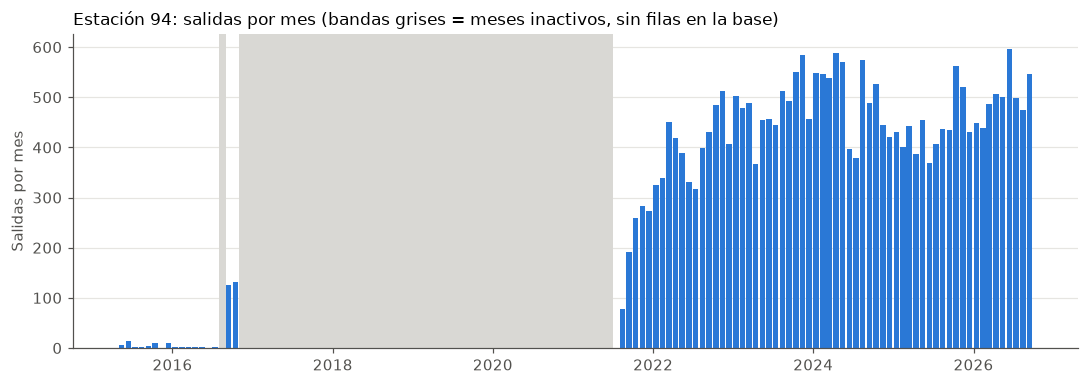

In [6]:
# Station 94: monthly departures over its whole life; inactive months shown as bands
station_id = 94
grid = base[base["station_id"] == station_id]
monthly = grid.groupby(grid["hour_start"].dt.to_period("M"))["departures"].sum()

# Every month between the first and the last; months missing from the grid are inactive
all_months = pd.period_range(monthly.index.min(), monthly.index.max(), freq="M")
monthly = monthly.reindex(all_months)
inactive = monthly.isna()

fig, ax = plt.subplots(figsize=(10, 3.6))
x = all_months.to_timestamp()
for month in x[inactive.to_numpy()]:
    ax.axvspan(month, month + pd.offsets.MonthBegin(1), color=INACTIVE, linewidth=0)
ax.bar(x, monthly.fillna(0), width=25, color=SERIES, align="edge")
ax.set_title(
    f"Estación {station_id}: salidas por mes (bandas grises = meses inactivos, sin filas en la base)",
    loc="left",
    fontsize=11,
)
ax.set_ylabel("Salidas por mes")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "1.04-lsg-station-94-lifecycle.png", dpi=150)
plt.show()

**Interpretación**

La estación 94 alterna periodos de operación con periodos largos sin ningún viaje (bandas grises). Esos meses **no aparecen en la base**: no son demanda cero, son periodos en que la estación no estaba operando. Si se rellenaran con 0, el modelo aprendería que esta estación casi no tiene demanda y recomendaría enviar menos bicicletas justo cuando sí opera.

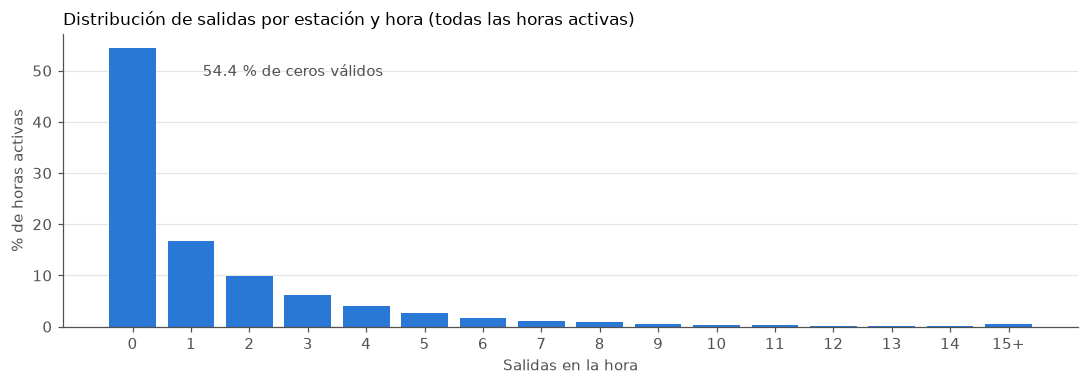

departures,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
% de horas,54.41,16.71,9.95,6.22,4.02,2.65,1.76,1.19,0.82,0.58,0.41,0.3,0.22,0.16,0.12,0.47


In [7]:
# Target distribution: share of active hours by number of departures
CAP = 15  # 15 or more are grouped in the last bar
values = base["departures"].clip(upper=CAP)
share = values.value_counts(normalize=True).sort_index() * 100

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(share.index, share.values, width=0.8, color=SERIES)
ax.set_xticks(range(CAP + 1), [str(v) for v in range(CAP)] + [f"{CAP}+"])
ax.set_xlabel("Salidas en la hora")
ax.set_ylabel("% de horas activas")
ax.set_title("Distribución de salidas por estación y hora (todas las horas activas)", loc="left", fontsize=11)
ax.annotate(
    f"{share.loc[0]:.1f} % de ceros válidos",
    xy=(0, share.loc[0]),
    xytext=(1.2, share.loc[0] * 0.9),
    color=MUTED,
    fontsize=10,
)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "1.04-lsg-departures-distribution.png", dpi=150)
plt.show()

share.round(2).to_frame("% de horas").T

**Interpretación**

El target está **muy concentrado en valores bajos**: más de la mitad de las horas activas tienen 0 salidas y la frecuencia cae rápidamente al aumentar el conteo, con una cola larga (máximo 207). Implicaciones para fases posteriores:

- Es un problema de **conteos con exceso de ceros**; un baseline razonable debe compararse contra predecir siempre 0 o el promedio histórico de la misma estación y hora.
- Las métricas porcentuales (MAPE) no sirven cuando el valor real es 0; conviene MAE/RMSE o métricas para conteos.
- La cola larga sugiere revisar eventos especiales (celda de horas máximas, más abajo).

### 3.1 Estadísticas del target y sobredispersión

**¿Qué se quiere saber?** Si la variabilidad del target es la que esperaría un modelo de conteos simple, o mucho mayor.

**Fundamento.** El modelo de conteos más simple es la distribución de **Poisson**, que asume que la varianza es igual a la media:

$$\text{Poisson:}\quad \operatorname{Var}(Y) = \mathbb{E}[Y] \qquad\Longrightarrow\qquad D = \frac{\operatorname{Var}(Y)}{\mathbb{E}[Y]} = 1$$

- $Y$: salidas de una estación en una hora.
- $\mathbb{E}[Y]$: promedio de salidas; $\operatorname{Var}(Y)$: varianza.
- $D$: **índice de dispersión**. Se lee: *"cuántas veces más varía el conteo de lo que asumiría Poisson"*.

$D \approx 1$ → Poisson es razonable. $D > 1$ → **sobredispersión**: hay más horas en 0 y más picos de lo que Poisson permite (por ejemplo, por diferencias entre estaciones, horas pico o eventos).

**Ejemplo sencillo:** cuatro horas con salidas 0, 0, 0 y 8 tienen media 2 y varianza (muestral) 16 → $D = 8$: mucho más irregular que cuatro horas con 2, 2, 2 y 2 ($D = 0$).

In [8]:
departures = base["departures"]
target_stats = pd.Series(
    {
        "media": departures.mean(),
        "varianza": departures.var(),
        "indice_dispersion (var/media)": departures.var() / departures.mean(),
        "asimetria (skewness)": departures.skew(),
        "pct_ceros": (departures == 0).mean() * 100,
    }
).round(3)
target_stats.to_frame("todas las horas activas")

,todas las horas activas
media,1.383
varianza,6.358
indice_dispersion (var/media),4.596
asimetria (skewness),4.301
pct_ceros,54.412


In [9]:
# Same analysis per station: is overdispersion only due to mixing different stations?
per_station = base.groupby("station_id")["departures"].agg(
    media="mean", varianza="var", pct_ceros=lambda x: (x == 0).mean() * 100
)
per_station["indice_dispersion"] = per_station["varianza"] / per_station["media"]
per_station[["media", "pct_ceros", "indice_dispersion"]].describe(
    percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]
).round(2)

,media,pct_ceros,indice_dispersion
count,486.00,486.00,486.00
mean,1.06,60.89,2.32
std,1.02,17.33,1.23
min,0.01,25.11,1.12
10%,0.22,37.76,1.35
25%,0.36,46.81,1.51
50%,0.76,60.20,2.00
75%,1.46,75.40,2.70
90%,2.18,83.04,3.56
max,8.10,99.65,15.48


**Interpretación**

- Con todas las horas activas: media ≈ 1.38, varianza ≈ 6.36 → **índice de dispersión ≈ 4.6** y asimetría ≈ 4.3 (cola larga a la derecha).
- **Por estación**, el índice baja pero **todas** las estaciones siguen por encima de 1 (mínimo ≈ 1.12, mediana ≈ 2.0). Parte de la sobredispersión global se explica por **mezclar estaciones con volúmenes muy distintos** (promedio por hora desde ≈ 0.01 hasta ≈ 8.1), pero dentro de cada estación sigue habiendo más variación que la de Poisson: la hora del día, el día de la semana y los eventos importan.
- El porcentaje de ceros también varía mucho entre estaciones (mediana ≈ 60 %, de ≈ 25 % a ≈ 100 %).

**Implicaciones para la Fase 2 (no se deciden aquí):**

1. El modelo necesita información de **estación** y de **calendario**; un único promedio global sería un mal baseline.
2. Si se usa un modelo de conteos, un Poisson simple probablemente se quede corto; conviene contemplar alternativas que admitan sobredispersión (por ejemplo, Binomial Negativa) o modelos de árboles con pérdida para conteos.
3. **Métricas de ML.** El MAPE se indetermina cuando $y_{s,t} = 0$ (más de la mitad de las horas), así que no sirve. Se propone:
   - **MAE**: error medio en salidas por hora, fácil de interpretar.
   - **WAPE** (*Weighted Absolute Percentage Error*), que sí admite ceros porque divide entre el total y no entre cada valor:
     $$\text{WAPE} = \frac{\sum_{s,t} |y_{s,t} - \hat{y}_{s,t}|}{\sum_{s,t} y_{s,t}}$$
     Se lee: *"del total de salidas reales, qué fracción se pronosticó mal"*. Ejemplo: reales 0, 2 y 8 (total 10), pronóstico 1, 2 y 6 → errores 1 + 0 + 2 = 3 → WAPE = 0.3.
   - **RMSE** como complemento: penaliza más los errores grandes (horas pico), lo cual importa porque una hora pico mal pronosticada deja estaciones vacías. Usado solo, puede llevar al modelo a sobreajustar los picos y descuidar las horas valle.
   - **Pérdida de entrenamiento** adecuada a conteos (Poisson o Tweedie) en lugar de MSE, por la sobredispersión y el exceso de ceros.
4. **Métrica de negocio (distinta de la de ML):** lo que importa a la operación es cuántas estaciones quedan vacías o llenas en horas pico y cuántos movimientos de rebalanceo se requieren. El pronóstico es un insumo; su evaluación final debería medirse en esos términos (fuera del alcance de la Fase 1).

### 3.2 Nota de métodos: qué técnicas no se aplican y por qué

El EDA de referencia del curso (notebooks de *Wine Quality*) usa técnicas pensadas para **variables numéricas continuas**. Se evaluaron para este problema y se descartan con justificación:

| Técnica | Por qué no aplica aquí |
|---|---|
| **Regla IQR para atípicos del target** | Con 54 % de ceros, Q1 = 0 y Q3 = 2: el límite superior es 5 y marcaría como "atípicas" al 6 % de las horas, que son simplemente horas pico normales. Los picos se revisan caso por caso (horas máximas). |
| **Mapas de correlación de Pearson/Spearman** | Las variables explicativas disponibles son **categóricas o cíclicas** (estación, hora, día de la semana, mes): una correlación lineal entre las salidas y la hora no tiene sentido (las 23:00 no están "lejos" de las 00:00). Se usan perfiles por grupo (promedio por hora, por día) en su lugar. |
| **Escalamiento o normalización** | No hay modelo todavía; además, cualquier transformación aprendida debe ajustarse solo con datos de entrenamiento después del corte temporal, para evitar fuga de información. |
| **Imputación de faltantes** | La base no tiene faltantes por construcción; los periodos sin operación no se imputan (no se fabrican etiquetas). |
| **Eliminación de picos extremos** | Los picos revisados son demanda real (muchos usuarios distintos, duraciones normales); eliminarlos ocultaría justo la demanda que más importa para el rebalanceo. |

In [10]:
# Hours with the most departures in the whole history
top = base.nlargest(10, "departures")[["station_id", "hour_start", "departures", "day_of_week", "hour"]]
top["estacion"] = top["station_id"].map(stations["snapshot_name"])
top["dia"] = top["hour_start"].dt.day_name()
top[["station_id", "estacion", "hour_start", "dia", "departures"]]

,station_id,estacion,hour_start,dia,departures
17249829,194,(GDL-127) Av. Vallarta / Av. de Los Arcos,2025-09-20 21:00:00,Saturday,207
17249828,194,(GDL-127) Av. Vallarta / Av. de Los Arcos,2025-09-20 20:00:00,Saturday,178
17254532,194,(GDL-127) Av. Vallarta / Av. de Los Arcos,2026-04-04 20:00:00,Saturday,149
17258229,194,(GDL-127) Av. Vallarta / Av. de Los Arcos,2026-09-05 21:00:00,Saturday,141
17254533,194,(GDL-127) Av. Vallarta / Av. de Los Arcos,2026-04-04 21:00:00,Saturday,132
17253188,194,(GDL-127) Av. Vallarta / Av. de Los Arcos,2026-02-07 20:00:00,Saturday,124
17253189,194,(GDL-127) Av. Vallarta / Av. de Los Arcos,2026-02-07 21:00:00,Saturday,121
17258228,194,(GDL-127) Av. Vallarta / Av. de Los Arcos,2026-09-05 20:00:00,Saturday,111
17250837,194,(GDL-127) Av. Vallarta / Av. de Los Arcos,2025-11-01 21:00:00,Saturday,109
17253860,194,(GDL-127) Av. Vallarta / Av. de Los Arcos,2026-03-07 20:00:00,Saturday,109


**Interpretación**

Las horas con más salidas del histórico se concentran en la **estación 194 (Av. Vallarta / Av. de Los Arcos)**, en **sábados entre 20:00 y 22:00**. En la hora máxima (2025-09-20 21:00, 207 salidas) se registraron 198 usuarios distintos, con duración mediana de 22 min y destinos variados, y solo 2 viajes con flag: **no parece un error de registro, sino un pico real**, probablemente asociado a un evento o actividad nocturna en la zona (pendiente de confirmar).

**Implicación:** estos picos no deben eliminarse como errores, pero son difíciles de pronosticar sin un calendario de eventos. Contraste con el 1.02 (Erik): el 2025-09-20 **no** aparece en su lista de días atípicos (`reports/1.02-erc-atypical-days.csv`), porque ese día el total del sistema fue normal: el pico es **local de una estación**, no del sistema. Por eso no se trata como día atípico, sino como demanda real de una estación (se considera en la decisión 7, sección 8).

### 3.3 Dependencia temporal: evidencia para el contrato de predicción y el baseline

**Pregunta:** ¿con qué anticipación conviene pronosticar y qué información del pasado predice mejor las salidas?

El contrato define un **corte**: la última hora del día $d$ cuyos datos se usan para pronosticar el día $d+1$. Dos opciones razonables:

| Opción | Corte | Ventaja | Costo |
|---|---|---|---|
| A | 23:59 del día $d$ | Usa todo el día $d$ | El pronóstico solo está listo después de medianoche |
| B | 22:00 del día $d$ | Deja tiempo para planear el rebalanceo nocturno | Pierde las últimas horas del día $d$ |

Para decidir, se miden dos cosas:

1. **Cuánta demanda cae al final del día** (lo que se pierde con un corte anticipado).
2. **Qué tan bien predice cada rezago**, usando predictores ingenuos (sin modelo) evaluados con WAPE y correlación:
   - $\hat{y}_{s,t} = y_{s,t-1}$: la hora anterior. **No está disponible** en un pronóstico de día siguiente; se incluye solo como referencia de cuánto aporta el pasado inmediato.
   - $\hat{y}_{s,t} = y_{s,t-24}$: ayer a la misma hora.
   - $\hat{y}_{s,t} = y_{s,t-48}$: hace dos días.
   - $\hat{y}_{s,t} = y_{s,t-168}$: hace una semana, mismo día y hora.
   - $\hat{y}_{s,t} = \frac{1}{4}\sum_{k=1}^{4} y_{s,t-168k}$: promedio de las últimas 4 semanas, mismo día y hora.

Se evalúa en el periodo reciente (2025-01 a 2026-09). Un rezago solo se usa si la estación estaba activa en esa hora pasada.

In [11]:
# Share of daily departures by hour of day (last 24 months: current network)
recent = base[base["hour_start"] >= "2024-10-01"]
hourly_share = recent.groupby("hour")["departures"].sum() / recent["departures"].sum() * 100
late_day = pd.Series(
    {
        "20:00-23:59": hourly_share.loc[20:23].sum(),
        "22:00-23:59": hourly_share.loc[22:23].sum(),
        "00:00-05:59": hourly_share.loc[0:5].sum(),
    }
).round(2)
late_day.to_frame("% de salidas diarias")

,% de salidas diarias
20:00-23:59,12.84
22:00-23:59,3.59
00:00-05:59,1.46


In [12]:
import numpy as np

# Naive predictors: value of the same station at an earlier hour.
# Lags are looked up by timestamp (not by row position), so hours outside the
# station's active window stay missing instead of borrowing a neighbour's value.
series = base.set_index(["station_id", "hour_start"])["departures"]
evaluation = base.loc[base["hour_start"] >= "2025-01-01", ["station_id", "hour_start", "departures"]]


def lagged(hours):
    keys = pd.MultiIndex.from_arrays(
        [evaluation["station_id"], evaluation["hour_start"] - pd.Timedelta(hours=hours)]
    )
    return series.reindex(keys).to_numpy(dtype=float)


predictors = {
    "hora anterior (t-1, no disponible día siguiente)": lagged(1),
    "ayer, misma hora (t-24)": lagged(24),
    "hace 2 días, misma hora (t-48)": lagged(48),
    "hace 1 semana, misma hora (t-168)": lagged(168),
    # DataFrame.mean skips missing weeks (e.g. a station active for less than 4 weeks)
    "promedio últimas 4 semanas, misma hora": pd.DataFrame(
        np.column_stack([lagged(168 * k) for k in range(1, 5)])
    ).mean(axis=1).to_numpy(),
}

actual = evaluation["departures"].to_numpy(dtype=float)
rows = []
for name, prediction in predictors.items():
    available = ~np.isnan(prediction)
    error = np.abs(actual[available] - prediction[available])
    rows.append(
        {
            "predictor": name,  # display label in Spanish (report language)
            "coverage": available.mean(),
            "MAE": error.mean(),
            "WAPE": error.sum() / actual[available].sum(),
            "correlation": np.corrcoef(actual[available], prediction[available])[0, 1],
        }
    )
naive_scores = pd.DataFrame(rows).set_index("predictor").round(3)
naive_scores

,coverage,MAE,WAPE,correlation
predictor,,,,
"hora anterior (t-1, no disponible día siguiente)",1.000,1.113,0.824,0.663
"ayer, misma hora (t-24)",1.000,1.071,0.792,0.638
"hace 2 días, misma hora (t-48)",0.999,1.157,0.856,0.576
"hace 1 semana, misma hora (t-168)",0.997,0.989,0.730,0.708
"promedio últimas 4 semanas, misma hora",0.997,0.846,0.625,0.790


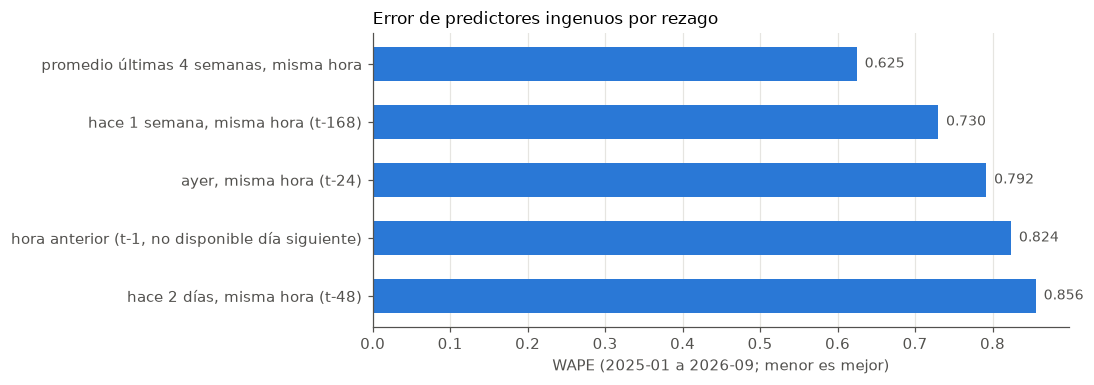

In [13]:
# WAPE by naive predictor (lower is better)
ordered = naive_scores["WAPE"].sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.barh(ordered.index, ordered.values, height=0.6, color=SERIES)
for y_pos, value in enumerate(ordered.values):
    ax.text(value + 0.01, y_pos, f"{value:.3f}", va="center", color=MUTED, fontsize=9)
ax.set_xlabel("WAPE (2025-01 a 2026-09; menor es mejor)")
ax.set_title("Error de predictores ingenuos por rezago", loc="left", fontsize=11)
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "1.04-lsg-naive-predictors-wape.png", dpi=150)
plt.show()

**Interpretación**

- **Demanda al final del día:** entre las 22:00 y las 23:59 ocurre ≈ 3.6 % de las salidas diarias (≈ 12.8 % entre 20:00 y 23:59). Un corte a las 22:00 deja fuera una parte pequeña de la información del día $d$.
- **El patrón semanal pesa más que el pasado inmediato:** "hace una semana, misma hora" (WAPE ≈ 0.73) es mejor que "ayer, misma hora" (≈ 0.79), e incluso que la hora anterior (≈ 0.82), que de todos modos no estaría disponible.
- **El mejor predictor ingenuo es el promedio de las últimas 4 semanas, mismo día y hora** (WAPE ≈ 0.63, correlación ≈ 0.79). Promediar varias semanas suaviza el ruido de una sola.
- Como referencia: predecir siempre 0 da WAPE = 1 y predecir el promedio global da ≈ 1.17; todos los rezagos son mucho mejores.

**Implicaciones:**

1. **Contrato de predicción:** la información más útil (rezagos de 168 h o más) está disponible con cualquiera de los dos cortes. Perder las últimas horas del día $d$ (opción B) tiene un costo bajo: esas horas aportan poca demanda y el rezago de 24 h es el que menos aporta entre los disponibles. → Evidencia para la decisión 0 de la sección 8.
2. **Baseline para la Fase 2:** el promedio de las últimas 4 semanas para la misma estación, día de la semana y hora (WAPE ≈ 0.63) es el punto de referencia que cualquier modelo deberá superar.
3. **Features candidatas:** rezagos semanales (168, 336, … h) y promedios por estación × día × hora calculados **solo con datos anteriores al corte**.

### 3.4 Sensibilidad del target a los viajes cortos (flags)

**Pregunta:** ¿excluir los viajes cortos cambia el target? ¿Esos viajes parecen demanda real o actividad operativa?

| Flag | Regla (PR1) |
|---|---|
| `flag_short_same_station` | Menos de 60 s y regresa a la misma estación |
| `flag_short_cross_station` | Menos de 60 s entre estaciones distintas |

**Método:**

1. **Caracterizar** cuándo y dónde ocurren (por año, por hora del día, por estación). Si se reparten de forma pareja, se parecen al comportamiento normal; si se concentran en horas o estaciones atípicas, sugieren actividad operativa (pruebas, mantenimiento, rebalanceo).
2. **Sensibilidad:** sobre la **misma grilla** de `station_hour_base`, recalcular las salidas excluyendo cada tipo de viaje y comparar media, % de ceros y horas que cambian. Se reutiliza `count_departures` de `mibici.station_hour` (no se duplica la lógica).

In [14]:
from mibici.station_hour import count_departures

# Only the columns needed for the flag analysis (interim trips, read-only)
flag_columns = ["flag_short_same_station", "flag_short_cross_station"]
trips = pd.read_parquet(
    INTERIM_DATA_DIR / "trips",
    columns=["started_at", "origin_station_id", "destination_station_id", *flag_columns],
)

# Share of flagged trips (%) per year: is it stable over time?
by_year = trips.groupby(trips["started_at"].dt.year)[flag_columns].mean().mul(100).round(2)
by_year.T

started_at,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
flag_short_same_station,7.89,3.61,2.79,2.25,2.45,2.71,2.97,3.38,4.23,3.87,2.88,2.41,3.41
flag_short_cross_station,0.00,0.02,0.11,0.05,0.05,0.05,0.12,0.14,0.17,0.25,0.22,0.18,0.40


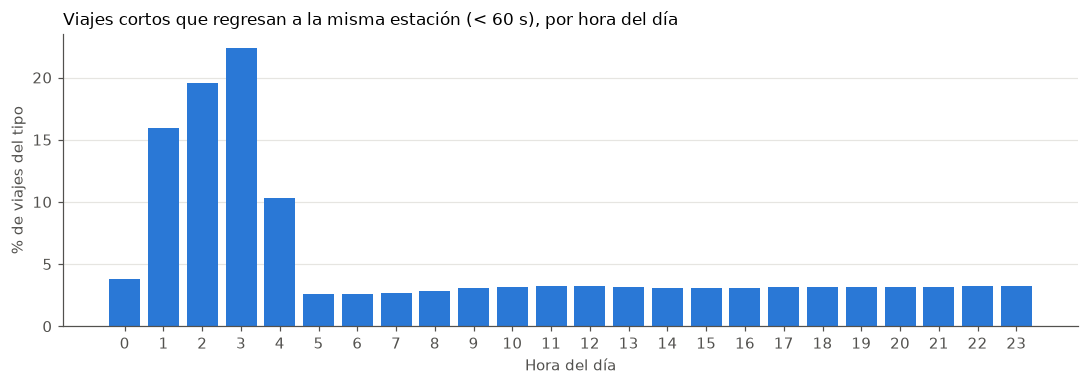

In [15]:
# Share of short same-station trips by hour of day (whole history)
by_hour = trips.groupby(trips["started_at"].dt.hour)["flag_short_same_station"].mean() * 100

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(by_hour.index, by_hour.values, width=0.8, color=SERIES)
ax.set_xticks(range(24))
ax.set_xlabel("Hora del día")
ax.set_ylabel("% de viajes del tipo")
ax.set_title(
    "Viajes cortos que regresan a la misma estación (< 60 s), por hora del día",
    loc="left",
    fontsize=11,
)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "1.04-lsg-short-same-station-by-hour.png", dpi=150)
plt.show()

In [16]:
# Concentration by origin station: share of short same-station trips per station
per_origin = trips.groupby("origin_station_id")["flag_short_same_station"].agg(
    trips="size", short_same="sum", share="mean"
)
per_origin["share"] = (per_origin["share"] * 100).round(2)
print("Median share per station (%):", per_origin["share"].median())
print("90th percentile per station (%):", per_origin["share"].quantile(0.9))
per_origin.sort_values("share", ascending=False).head(5)

Median share per station (%): 3.19
90th percentile per station (%): 4.285


,trips,short_same,share
origin_station_id,,,
124,63,44,69.84
405,3,1,33.33
99,145,27,18.62
465,142,16,11.27
97,1178,127,10.78


In [17]:
# Sensitivity: recount departures on the SAME grid after excluding each flag type.
# Keeping the grid fixed isolates the effect on the target from any change in active windows.
grid = base[["station_id", "hour_start", "departures"]]


def target_without(mask):
    counts = count_departures(trips[~mask]).rename(columns={"departures": "variant"})
    merged = grid.merge(counts, on=["station_id", "hour_start"], how="left")
    return merged["variant"].fillna(0)


variants = {
    "completo (todos los viajes)": grid["departures"],
    "sin short_same_station": target_without(trips["flag_short_same_station"].to_numpy()),
    "sin short_cross_station": target_without(trips["flag_short_cross_station"].to_numpy()),
    "sin ambos": target_without(
        (trips["flag_short_same_station"] | trips["flag_short_cross_station"]).to_numpy()
    ),
}

sensitivity = pd.DataFrame(
    {
        name: {
            "total_salidas": int(values.sum()),
            "media_por_hora": values.mean(),
            "pct_ceros": (values == 0).mean() * 100,
            "pct_horas_que_cambian": (values != grid["departures"]).mean() * 100,
        }
        for name, values in variants.items()
    }
).T
sensitivity["cambio_media_%"] = (
    sensitivity["media_por_hora"] / sensitivity.loc["completo (todos los viajes)", "media_por_hora"] - 1
) * 100
sensitivity.round(4)

,total_salidas,media_por_hora,pct_ceros,pct_horas_que_cambian,cambio_media_%
completo (todos los viajes),39078226.0,1.3835,54.4119,0.0000,0.0000
sin short_same_station,37872554.0,1.3408,54.5599,3.6025,-3.0853
sin short_cross_station,39014490.0,1.3812,54.4442,0.2076,-0.1631
sin ambos,37808818.0,1.3385,54.5938,3.7781,-3.2484


**Interpretación**

- **Magnitud:** `flag_short_same_station` son ≈ 3.1 % de los viajes; excluirlos baja la media del target ≈ 3.1 %, sube los ceros ≈ 0.15 pp y cambia ≈ 3.6 % de las horas. `flag_short_cross_station` son ≈ 0.16 %: su efecto en el target es despreciable (≈ 0.2 % de la media).
- **Patrón horario:** durante el día, ≈ 3 % de los viajes son de este tipo de forma pareja; **entre la 1:00 y las 4:00 sube a 16–22 %**. A esa hora casi no hay usuarios: el patrón es compatible con **actividad operativa** (pruebas, mantenimiento, personal de rebalanceo), no con demanda.
- **Por estación:** el reparto es parejo (mediana ≈ 3.2 %, p90 ≈ 4.3 %), con una excepción: la **estación 124** (sin metadatos, activa 2016–2020) tiene ≈ 70 %, lo que sugiere una estación de pruebas o taller.
- **Por año:** 7.9 % en 2014 (arranque del sistema) y 2–4 % después; `short_cross_station` crece hasta 0.40 % en 2026.
- **Desde el rebalanceo:** una bicicleta que sale y vuelve al mismo anclaje en menos de 60 s **no cambia el inventario** de la estación.

**Evidencia para las decisiones 2 y 3 (sección 8):** el efecto en el target es pequeño en ambos casos, así que la decisión es de bajo riesgo. A favor de excluir `short_same_station`: el pico nocturno, la estación 124 y que no mueve bicicletas. A favor de conservarlos: una parte puede ser demanda real frustrada (bicicleta con falla). `short_cross_station` es físicamente poco plausible y su efecto es despreciable.

## 4. Patrones temporales: verificación cruzada del 1.01 y horario de servicio

> Esta sección se elaboró como **plan B** (por Leonardo Santos García) mientras el notebook 1.01 no estaba disponible. El 1.01 se recibió después (24-oct, 17:02 h) y es la **referencia** para los patrones temporales (sección 7.1). Esta sección se conserva como **verificación cruzada reproducible** desde `station_hour_base` y aporta el análisis del **horario de servicio** (decisión 11), que no estaba en el alcance del 1.01.

**Preguntas:** ¿en qué horas opera el sistema? ¿Hay horas pico claras y difieren entre días laborales y fin de semana? ¿El patrón horario es estable en el tiempo?

**Datos:** `station_hour_base` (perfiles en los últimos 24 meses, 2024-10 a 2026-09, para reflejar la red actual) y `interim_v1` (salidas por hora y año, para el horario de servicio).

In [18]:
# Service hours: departures per hour of day and year (hours near the night gap)
trips_hours = pd.read_parquet(INTERIM_DATA_DIR / "trips", columns=["started_at"])
service = pd.crosstab(trips_hours["started_at"].dt.hour, trips_hours["started_at"].dt.year)
service.index.name = "hora"
service.loc[[23, 0, 1, 2, 3, 4, 5, 6]]

started_at,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
hora,,,,,,,,,,,,,
23,389,6898,14352,36912,47920,59909,29671,35424,49536,50866,56750,54664,42293
0,13,625,82,17,18,42,11,13885,24573,26827,30323,27927,22304
1,1,204,13,8,5,0,0,8,6,6,12,11,96
2,0,115,18,2,2,1,0,0,0,0,0,0,10
3,0,57,18,0,0,0,0,0,0,0,0,0,1
4,0,41,6,1,0,5,0,0,0,35,0,0,9
5,2,358,59,1,0,20,2,10254,21148,25333,34238,36703,29024
6,173,7585,15891,51590,72124,106127,61699,63892,98657,115448,124919,126771,99503


**Interpretación: horario de servicio**

- **Entre la 1:00 y las 4:59 prácticamente no hay salidas en ningún año** (decenas de registros contra decenas de miles en las horas vecinas): el sistema está **cerrado** de madrugada.
- **Hasta 2020** tampoco hay actividad relevante a las 0:00 ni a las 5:00: el servicio opera aproximadamente de **6:00 a 24:00 (18 h)**. **Desde 2021** se agregan las 0:00 y las 5:00: de **5:00 a 1:00 (20 h)**.
- Los pocos registros en horario cerrado coinciden con el pico de viajes cortos de la sección 3.4: son mayormente actividad operativa.
- **Implicación para el target:** en `station_hour_base`, las horas de 1:00 a 4:59 son el ≈ 16.7 % de las filas y el ≈ 30.6 % de todos los ceros. **No son demanda cero: son horas sin servicio** (la misma regla de ceros válidos, aplicada al horario). Sin ellas, el % de ceros baja de ≈ 54.4 % a ≈ 45.3 %. → Evidencia para la decisión 11.

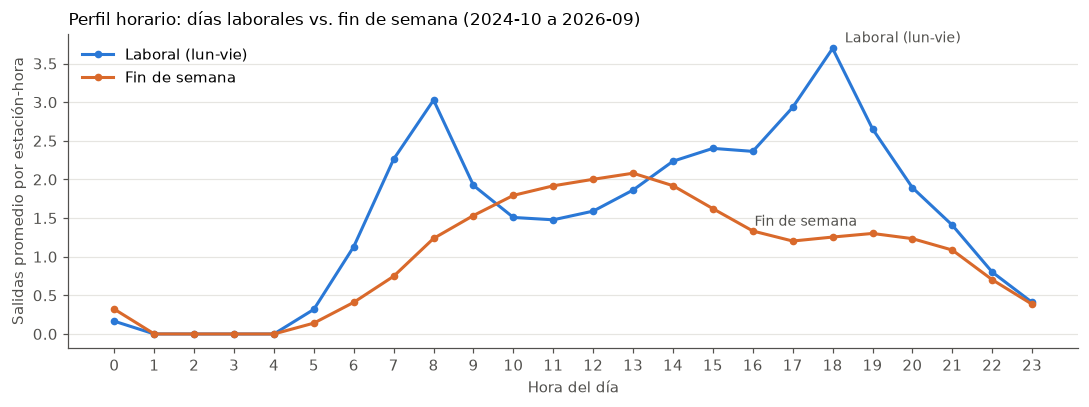

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
Laboral (lun-vie),0.16,0.0,0.0,0.0,0.0,0.32,1.13,2.26,3.03,1.92,...,2.24,2.40,2.36,2.93,3.70,2.66,1.89,1.41,0.8,0.41
Fin de semana,0.32,0.0,0.0,0.0,0.0,0.14,0.41,0.75,1.24,1.53,...,1.92,1.62,1.33,1.20,1.25,1.30,1.23,1.09,0.7,0.38


In [19]:
# Hourly profile: mean departures per station-hour, weekdays vs weekend (last 24 months)
recent = base[base["hour_start"] >= "2024-10-01"]
profile = recent.groupby(["hour", "is_weekend"])["departures"].mean().unstack()
profile.columns = ["Laboral (lun-vie)", "Fin de semana"]

WEEKEND = "#d9692b"  # second series color
fig, ax = plt.subplots(figsize=(10, 3.8))
# Direct labels where each curve is clear of the other: weekday at its 18:00 peak, weekend above its 17:00 trough
label_spots = [(18, (8, 4)), (17, (-25, 10))]
for column, color, (hour, offset) in zip(profile.columns, [SERIES, WEEKEND], label_spots):
    ax.plot(profile.index, profile[column], color=color, linewidth=2, marker="o", markersize=4)
    ax.annotate(column, (hour, profile.loc[hour, column]), xytext=offset,
                textcoords="offset points", color=MUTED, fontsize=9)
ax.set_xticks(range(24))
ax.set_xlabel("Hora del día")
ax.set_ylabel("Salidas promedio por estación-hora")
ax.set_title("Perfil horario: días laborales vs. fin de semana (2024-10 a 2026-09)", loc="left", fontsize=11)
ax.legend(profile.columns, loc="upper left", frameon=False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "1.04-lsg-hourly-profile-weekday-weekend.png", dpi=150)
plt.show()
profile.round(2).T

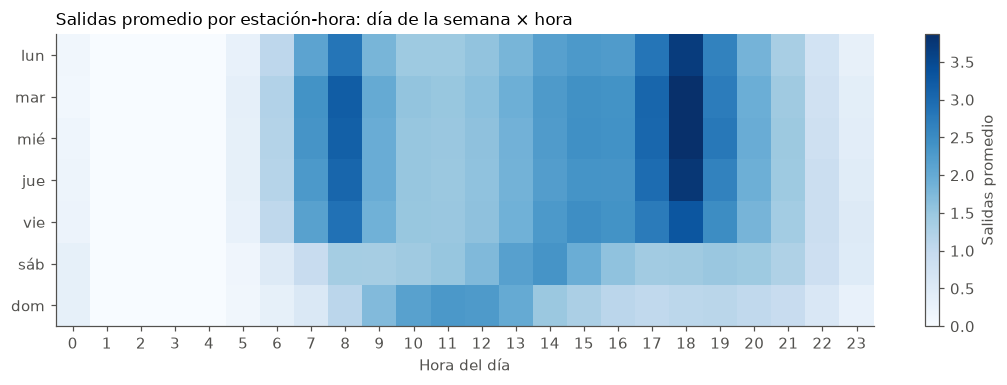

In [20]:
# Heatmap: mean departures per station-hour by day of week x hour (last 24 months)
heat = recent.pivot_table(index="day_of_week", columns="hour", values="departures", aggfunc="mean")
days = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]

fig, ax = plt.subplots(figsize=(10, 3.6))
image = ax.imshow(heat.to_numpy(), aspect="auto", cmap="Blues")
ax.set_xticks(range(24))
ax.set_yticks(range(7), days)
ax.set_xlabel("Hora del día")
ax.set_title("Salidas promedio por estación-hora: día de la semana × hora", loc="left", fontsize=11)
ax.grid(False)
fig.colorbar(image, ax=ax, label="Salidas promedio")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "1.04-lsg-heatmap-dow-hour.png", dpi=150)
plt.show()

In [21]:
# Stability: compare the SHAPE of the weekday hourly profile (share of daily departures per hour)
def hourly_shape(frame):
    totals = frame.groupby("hour")["departures"].sum()
    return totals / totals.sum()


weekdays = ~base["is_weekend"]
early = hourly_shape(base[weekdays & (base["hour_start"] >= "2018-01-01") & (base["hour_start"] < "2020-01-01")])
late = hourly_shape(base[weekdays & (base["hour_start"] >= "2024-10-01")])
print(f"Correlación del perfil laboral 2018-2019 vs 2024-2026: {early.corr(late):.3f}")
print(f"Mayor diferencia por hora: {(early - late).abs().max() * 100:.2f} pp (hora {(early - late).abs().idxmax()})")

Correlación del perfil laboral 2018-2019 vs 2024-2026: 0.982
Mayor diferencia por hora: 1.32 pp (hora 7)


**Interpretación: patrones temporales**

- **Días laborales: dos picos claros**, a las **8:00** (≈ 3.0 salidas por estación-hora) y a las **18:00** (≈ 3.7), con un valle a media mañana. Es el patrón típico de traslados casa–trabajo/escuela.
- **Fin de semana: una sola meseta** al mediodía (12:00–14:00, ≈ 2.0), sin picos de traslado y con menor volumen.
- **Domingo por la mañana:** de 10:00 a 12:00 el domingo supera al sábado (en el mapa de calor), un patrón propio de ese día; una hipótesis es la actividad recreativa dominical (por ejemplo, la Vía RecreActiva), pendiente de confirmar.
- **Por día de la semana:** martes y miércoles son los más altos (≈ 1.54 salidas por estación-hora); sábado (≈ 1.07) y domingo (≈ 0.95) los más bajos.
- **Estabilidad:** la forma del perfil laboral de 2018–2019 y la de 2024–2026 tienen correlación ≈ 0.98; la mayor diferencia es de ≈ 1.3 pp (7:00). El patrón horario es **estable en el tiempo**, aunque el volumen cambie.

**Evidencia para la decisión 1:** la demanda cambia mucho **dentro del día** (de ≈ 0.4 a ≈ 3.7 salidas por estación-hora en día laboral) y la forma es distinta entre laborales y fin de semana. Agregar por día perdería justo los picos que más importan para el rebalanceo. La granularidad **estación × hora** está justificada, con `hour`, `day_of_week` e `is_weekend` como variables de calendario.

## 5. Estacionalidad y anomalías (mínimo)

No se requiere plan B: el notebook 1.02 (Erik) fue integrado. Ver sección 7.2.

## 6. Expansión de estaciones (mínimo)

No se requiere plan B: el notebook 1.03 (José Emmanuel) fue integrado. Ver sección 7.3.

## 7. Resultados de los PR del equipo

| Notebook | Autor | PR | Entrega | Estado |
|---|---|---|---|---|
| [`1.01-jedm-temporal-patterns.ipynb`](1.01-jedm-temporal-patterns.ipynb) | José Eduardo De Moraes López | #5 | 24-oct, 17:02 h (después de la fecha límite de 15:00 h) | Integrado a `main` |
| [`1.02-erc-seasonality-anomalies.ipynb`](1.02-erc-seasonality-anomalies.ipynb) | Erik Román Cortez | #4 | 24-oct, 16:29 h (después de la fecha límite de 15:00 h) | Integrado a `main` |
| [`1.03-jevg-station-expansion.ipynb`](1.03-jevg-station-expansion.ipynb) | José Emmanuel Vázquez Galán | #3 | 23-oct, 22:57 h | Integrado a `main` |

### 7.0 Cómo se integran los notebooks del equipo

Este notebook **no repite** el análisis de los compañeros: lo usa como evidencia, lo verifica contra la base común (`station_hour_base`) y lo lleva a una decisión. Se usan tres niveles de referencia:

| Nivel | Qué es | Cómo se hace aquí |
|---|---|---|
| 1. Cita con enlace | Enlace al notebook, sección e **ID de celda** (los IDs del formato `.ipynb` son estables) | Cada hallazgo citado indica su origen, p. ej. *1.03, sección 4.1, celda `2dcf102a`* |
| 2. Reutilizar sus archivos | Leer los archivos que ellos generaron | CSV de días atípicos de Erik y figuras de los tres notebooks |
| 3. Leer los resultados de sus celdas | Extraer desde código la tabla que muestra una celda, por su ID | `cell_table(...)`: las cifras del 1.03 no se escriben a mano |

**Qué se toma de cada notebook y para qué:**

| Notebook | Se toma | Nivel | Alimenta la decisión |
|---|---|---|---|
| 1.01 | Respuestas a las 5 preguntas (celda `969c437e`) y figuras de perfil y estabilidad | 1 y 2 | 1 (granularidad) |
| 1.02 | Hallazgos (celda `8d0b8375`), índice contra 2019 (celda `9da27158`), CSV de días atípicos y figuras | 1 y 2 | 4, 5, 6, 7 (ventana, 2020–2021, días atípicos) |
| 1.03 | Tablas de intensidad, ceros y maduración (celdas `2dcf102a`, `336ec390`, `b4e027e7`) y figura de maduración | 1, 2 y 3 | 8 (estaciones nuevas) |

In [22]:
import nbformat
from bs4 import BeautifulSoup

from mibici.config import PROJ_ROOT

NOTEBOOKS_DIR = PROJ_ROOT / "notebooks"
NB_101 = "1.01-jedm-temporal-patterns.ipynb"
NB_102 = "1.02-erc-seasonality-anomalies.ipynb"
NB_103 = "1.03-jevg-station-expansion.ipynb"


def cell_table(notebook, cell_id, position=0):
    # Return the table displayed by a teammate's notebook cell, located by its stable cell id.
    nb = nbformat.read(NOTEBOOKS_DIR / notebook, as_version=4)
    cell = next((c for c in nb.cells if c.get("id") == cell_id), None)
    if cell is None:
        raise LookupError(f"{notebook}: cell {cell_id} not found (was it deleted or rebuilt?)")
    tables = [o["data"]["text/html"] for o in cell.get("outputs", []) if "text/html" in o.get("data", {})]
    if len(tables) <= position:
        raise LookupError(f"{notebook}: cell {cell_id} has no table output (was it saved without outputs?)")

    # Parse pandas' HTML table with the standard-library parser (no lxml/html5lib dependency)
    soup = BeautifulSoup(tables[position], "html.parser")
    header = [th.get_text(strip=True) for th in soup.find("thead").find("tr").find_all("th")]
    rows = [
        [td.get_text(strip=True) for td in tr.find_all(["th", "td"])]
        for tr in soup.find("tbody").find_all("tr")
    ]
    table = pd.DataFrame(rows, columns=header).set_index(header[0])
    return table.apply(pd.to_numeric, errors="coerce").fillna(table)

### 7.1 Patrones temporales (1.01, José Eduardo)

**Pregunta:** ¿cómo cambian las salidas por hora y día de la semana, y justifica eso la unidad estación × hora?

**Método del 1.01:** promedios de salidas por día (no totales) por hora, por día de la semana y en el cruce día × hora, para todo el sistema; comparación del perfil horario normalizado entre 2018–2019 y 2024–2026.

**Hallazgos (1.01, sección 5, celda `969c437e`):**

- Dos picos claros: **08:00** y **18:00** (el máximo del día); actividad casi nula de 01:00 a 04:00.
- Días laborales con perfil **bimodal** de traslados; fin de semana **unimodal**, con pico alrededor de las 13:00.
- Martes a jueves son los días más altos; sábado ≈ −34 % y domingo ≈ −45 % frente a mitad de semana (totales del sistema, 2018–2026).
- El perfil horario normalizado es casi idéntico en 2018–2019 y 2024–2026 → **la unidad estación × hora está justificada**.
- Recomienda `hour`, `day_of_week`, `is_weekend` y su interacción; codificación cíclica para modelos lineales.

![1.01 — Perfil laboral vs. fin de semana (José Eduardo)](../reports/figures/1.01-jedm-weekday-vs-weekend.png)

![1.01 — Estabilidad del perfil horario (José Eduardo)](../reports/figures/1.01-jedm-profile-stability.png)

**Verificación cruzada con la base (sección 4):** los picos (08:00 y 18:00), el perfil bimodal/unimodal y la estabilidad (correlación ≈ 0.98 entre periodos) **coinciden**. La caída del fin de semana es menor en la base (sábado ≈ −30 %, domingo ≈ −38 %) porque la sección 4 usa salidas **por estación-hora** en los últimos 24 meses, mientras que el 1.01 usa totales del sistema en 2018–2026; la conclusión es la misma.

**Revisión de reproducibilidad (resuelta):**

1. La primera versión del 1.01 (PR #5) leía `data/interim/temporal_summary.parquet` sin el código que lo genera. Tras la revisión, el autor agregó esa generación desde `data/interim/trips` (**PR #6**, commit `0feb3d8`). Se verificó ejecutándola desde cero: produce las mismas **61,906** filas (2018-01-01 a 2026-09-30). El notebook ya es reproducible.
2. `seaborn`, que usa el 1.01, no estaba declarado en `environment.yml`; quedó agregado (commits `77c8787` y `0feb3d8`, cambio idéntico).
3. El PR #5 modificó una línea de `references/data_manifest.csv` (estado `existing` → `downloaded`, sin cambio de hash), efecto de ejecutar `make data`.
4. Observaciones menores comunicadas en el PR #6: el resumen se reutiliza si ya existe (podría quedar desactualizado si se regenera interim) y los promedios del 1.01 corresponden a **2018–2026**, no a todo el histórico.

**Evidencia para la decisión 1:** granularidad estación × hora.

### 7.2 Estacionalidad y anomalías (1.02, Erik)

**Pregunta:** ¿hay estacionalidad, días atípicos o periodos especiales (2020–2021) que deban tratarse aparte?

**Método del 1.02:** series diaria y mensual normalizadas por **salidas por día por estación activa** (para no confundir expansión con demanda); índice estacional por mes con años completos, excluyendo 2020–2021 (celda `dafaf8fa`); índice de cada mes contra el mismo mes de 2019 (celda `9da27158`); días atípicos con la mediana de las 8 semanas previas del mismo día de la semana, umbrales 0.5 y 1.5, clasificados con un calendario de festivos de México y fuentes externas (celdas `da90d7f8` y `e06fb954`).

**Hallazgos (1.02, sección 5, celda `8d0b8375`) y decisión a la que alimentan:**

| Hallazgo | Decisión |
|---|---|
| Estacionalidad mensual moderada y estable: octubre el mes más alto (índice 1.11), diciembre el más bajo (0.88); los meses bajos coinciden con vacaciones | 10: incluir `month` (y, en Fase 2, una variable de periodo vacacional) |
| 2020–2021 es un régimen distinto: caída de 64 % por estación en abril de 2020 y un 2021 de transición | 6: tratar 2020–2021 aparte |
| Desde 2022 la demanda por estación forma un régimen relativamente estable en ≈ 0.70–0.80 del nivel de 2019 (2022 aún en recuperación: 0.66 a 0.93) | 4 y 5: **recomienda entrenar desde 2022-01** |
| 136 días atípicos (3.2 %): 97 de los 105 bajos son festivos o vacaciones recurrentes (comportamiento real y predecible) | 7: no excluir festivos; modelarlos con calendario |
| 3 eventos extraordinarios no recurrentes: huracán Patricia (2015-10-23) y bloqueos en Jalisco (2026-02-22 y 2026-02-23) | 7: marcarlos y excluirlos de entrenamiento y evaluación |
| Las expansiones de la red (2016, 2023, 2026) generan escalones de nivel que el detector confunde con anomalías | Limitación del método |

![1.02 — Serie mensual: total, estaciones activas y salidas por estación (Erik)](../reports/figures/1.02-erc-monthly-series.png)

![1.02 — 2020–2021 y años recientes frente a 2019 (Erik)](../reports/figures/1.02-erc-covid-vs-2019.png)

**Contraste con la integración:**

- El 1.02 reporta que la cobertura horaria diaria pasa de ≈ 18 h a ≈ 24 h hacia 2023, midiendo del primer al último viaje del día. La sección 4 muestra que **el horario cerrado de 1:00 a 4:59 se mantiene en todos los años**: lo que cambia (desde 2021) es que se agregan las 0:00 y las 5:00, de ≈ 18 h a ≈ 20 h de servicio. La medición "primer–último viaje" no detecta el hueco nocturno porque hay viajes a las 0:xx y a las 23:xx. Esto no invalida ninguna conclusión del 1.02.
- La recomendación de iniciar en 2022-01 es coherente con el índice contra 2019; como 2022 todavía muestra recuperación, la decisión 4 contrasta **2022-01** contra **2023-01** como inicio.

**Reutilización de su lista de días atípicos (nivel 2):** la celda siguiente lee el CSV que generó el 1.02 y define, a partir de él, los eventos extraordinarios a marcar.

In [23]:
# Level 2: reuse the atypical-days list produced by notebook 1.02 (Erik)
atypical = pd.read_csv(REPORTS_DIR / "1.02-erc-atypical-days.csv", parse_dates=["fecha"])
print(f"Atypical days in 1.02: {len(atypical)}")
display(pd.crosstab(atypical["clasificacion"], atypical["tipo"], margins=True))

# Extraordinary, non-recurring events identified in the 1.02 text (section 4.5). In its CSV they are
# still labelled "por explicar" with an empty cause, so the cause is documented here explicitly.
EXTRAORDINARY_EVENTS = {
    "2015-10-23": "Huracán Patricia toca tierra en Jalisco",
    "2026-02-22": "Bloqueos en Jalisco",
    "2026-02-23": "Bloqueos en Jalisco",
}
events = atypical.set_index("fecha").loc[pd.to_datetime(list(EXTRAORDINARY_EVENTS))]
events["causa_documentada"] = list(EXTRAORDINARY_EVENTS.values())
assert len(events) == len(EXTRAORDINARY_EVENTS), "An event date is missing from the 1.02 list"
events[["dia", "salidas", "esperado", "cociente", "clasificacion", "causa_documentada"]]

Atypical days in 1.02: 136


tipo,alto,bajo,All
clasificacion,,,
comportamiento real (calendario),0,97,97
por explicar,31,8,39
All,31,105,136


,dia,salidas,esperado,cociente,clasificacion,causa_documentada
fecha,,,,,,
2015-10-23,viernes,524,1650.0,0.32,por explicar,Huracán Patricia toca tierra en Jalisco
2026-02-22,domingo,2275,8712.0,0.26,por explicar,Bloqueos en Jalisco
2026-02-23,lunes,3676,13423.0,0.27,por explicar,Bloqueos en Jalisco


**Interpretación**

- La lista del 1.02 tiene 136 días atípicos; casi todos los bajos son **festivos o vacaciones** (comportamiento real y recurrente), por lo que **no se excluyen**: son demanda que el modelo debe aprender con variables de calendario.
- Los 3 **eventos extraordinarios** (huracán Patricia y los bloqueos de febrero de 2026) caen a ≈ 26–32 % de lo esperado y no son predecibles con el calendario. Se proponen para **marcar y excluir** del entrenamiento y la evaluación (decisión 7). Su causa se documenta aquí porque en el CSV del 1.02 quedó vacía.
- Los picos locales de una sola estación (estación 194, sección 3) no aparecen en esta lista, que mide el total del sistema: no son días atípicos y se conservan.

### 7.3 Expansión de estaciones (1.03, José Emmanuel)

**Pregunta:** ¿cómo se comportan las 100 estaciones nuevas de 2026 frente a las consolidadas?

**Método del 1.03:** compara ambos grupos en los mismos meses (2026-01 a 2026-09), normaliza por exposición (salidas por estación-día elegible), estima ceros horarios sin construir la grilla completa y analiza maduración por edad y cohortes. Ventana activa definida **por mes**.

**Hallazgos (1.03, secciones 4–6):** las nuevas tienen ≈ 1/4 de la intensidad de las consolidadas (celda `2dcf102a`), más horas sin salidas (celda `336ec390`) y una curva de maduración creciente (celda `b4e027e7`); recomienda evaluar por separado nuevas y consolidadas y tratar el *cold start* (celda `6cb69e35`).

![1.03 — Curva de maduración de estaciones nuevas (José Emmanuel)](../reports/figures/1.03-jevg-maturation-curve.png)

**Verificación con `station_hour_base` (nivel 3):** la ventana por mes incluye, en el primer mes de cada estación nueva, las horas anteriores a su apertura. Las celdas siguientes leen las tablas del 1.03 directamente de su notebook y las comparan con la base, que usa bordes por día.

In [24]:
# Recompute the 1.03 comparison with the day-level active window of station_hour_base
period = base[(base["hour_start"] >= "2026-01-01") & (base["hour_start"] < "2026-10-01")]
lifecycle = stations[["is_new_station", "is_retired_by_activity", "first_active_month"]]
period = period.join(lifecycle, on="station_id")

consolidated = (
    ~period["is_new_station"]
    & (period["first_active_month"] < pd.Period("2026-01", freq="M"))
    & ~period["is_retired_by_activity"]
)
period["group"] = np.select([period["is_new_station"], consolidated], ["new", "consolidated"], "other")
period = period[period["group"] != "other"]

groups = period.groupby("group").agg(
    eligible_hours=("departures", "size"),
    departures=("departures", "sum"),
    zero_share=("departures", lambda x: (x == 0).mean() * 100),
)
groups["departures_per_station_day"] = groups["departures"] / (groups["eligible_hours"] / 24)

# Values reported by notebook 1.03 (month-level window), read from its cell outputs (level 3)
labels_103 = {"Consolidada": "consolidated", "Nueva": "new"}
intensity_103 = cell_table(NB_103, "2dcf102a").rename(index=labels_103)  # 1.03, section 4.1
zeros_103 = cell_table(NB_103, "336ec390").rename(index=labels_103)  # 1.03, section 4.3
groups["1.03_eligible_hours"] = intensity_103["hours"]
groups["1.03_departures_per_station_day"] = intensity_103["per_day"].round(2)
groups["1.03_zero_share"] = zeros_103["zero_pct"].round(2)
groups.round(2).T

group,consolidated,new
eligible_hours,2407272.00,217536.00
departures,3262622.00,98685.00
zero_share,53.58,74.57
departures_per_station_day,32.53,10.89
1.03_eligible_hours,2407368.00,258120.00
1.03_departures_per_station_day,32.53,9.18
1.03_zero_share,53.58,78.57


In [25]:
# Maturation curve: months since first activity, day-level exposure
new_stations = period[period["group"] == "new"].copy()
months_since_first = new_stations["hour_start"].dt.to_period("M") - new_stations["first_active_month"]
new_stations["age_months"] = months_since_first.apply(lambda offset: offset.n)

maturation = new_stations.groupby("age_months").agg(
    stations=("station_id", "nunique"),
    eligible_hours=("departures", "size"),
    departures=("departures", "sum"),
)
maturation["departures_per_station_day"] = maturation["departures"] / (maturation["eligible_hours"] / 24)
# Maturation reported by 1.03, read from its cell output (level 3; 1.03, section 4.2)
maturation_103 = cell_table(NB_103, "b4e027e7").set_index("edad_meses")
maturation["1.03_departures_per_station_day"] = maturation_103["salidas_por_dia"].round(2)
maturation.round(2)

,stations,eligible_hours,departures,departures_per_station_day,1.03_departures_per_station_day
age_months,,,,,
0,100,32976,9418,6.85,3.08
1,99,72792,29924,9.87,9.83
2,84,61848,27485,10.67,10.67
3,57,41280,22408,13.03,13.01
4,12,8640,9450,26.25,26.25


**Interpretación** (las cifras del 1.03 se leen directamente de sus celdas `2dcf102a`, `336ec390` y `b4e027e7`; si su notebook se vuelve a ejecutar, esta comparación se actualiza sola)

| Indicador | 1.03 (por mes) | `station_hour_base` (por día) |
|---|---|---|
| Consolidadas: salidas/estación-día | 32.53 | 32.53 (idéntico) |
| Consolidadas: % ceros | 53.58 % | 53.58 % (idéntico) |
| Nuevas: horas elegibles | 258,120 | 217,536 (≈ 40,600 horas previas a la apertura) |
| Nuevas: salidas/estación-día | 9.18 | 10.89 |
| Nuevas: % ceros | 78.57 % | 74.57 % |
| Edad 0 (primer mes) | 3.08 | 6.85 |

- Las consolidadas coinciden exactamente: ambos métodos son consistentes cuando no hay aperturas a mitad de mes.
- Para las nuevas, la ventana por mes **subestima su intensidad y sobrestima sus ceros**, sobre todo en el primer mes: la edad 0 pasa de 3.08 a 6.85 salidas por estación-día. Parte del salto entre la edad 0 y la 1 que parecía maduración era exposición antes de la apertura.
- **Las conclusiones de 1.03 se mantienen:** las nuevas operan con ≈ 1/3 de la intensidad de las consolidadas y más ceros, y la intensidad crece con la edad. El cruce del 80 % a la edad 4 se apoya en una sola cohorte de 12 estaciones (mayo), así que no sirve como umbral general.
- **Evidencia para la decisión 8 (estaciones nuevas):** tratarlas por separado en la evaluación y considerar un historial mínimo para el entrenamiento, con base en la curva de maduración.

## 8. Decisiones

Cada decisión se documenta con **decisión · evidencia · justificación · limitación · implementación**. La columna *implementación* indica la constante o función de `mibici/processed.py` que la aplica; el código cita a su vez esta sección. La celda 8.2 verifica automáticamente que ambos coincidan.

> **Problema de negocio:** Pronosticar viajes iniciados por estación y por hora para el día siguiente, con el objetivo de apoyar la planeación del rebalanceo de bicicletas.

### 8.1 Revisión previa a la decisión 3: viajes cortos entre estaciones distintas

**Criterio acordado:** se compara cada viaje de menos de 60 s entre estaciones distintas con la **mediana de duración de su misma pareja origen → destino (mismo sentido) y año**.

| Parámetro | Valor |
|---|---|
| Referencia | Viajes con duración positiva de la misma pareja, sentido y año |
| Mínimo de referencia | 30 viajes |
| Candidato a exclusión | Duración inferior al 10 % de la mediana de la pareja |
| Sin referencia suficiente | Se conserva y mantiene el flag |
| Resolución al minuto (2023-11, 2024-09, 2024-10) | Revisión separada: se conserva |
| Interim | Todos los viajes permanecen |

La celda siguiente aplica la **misma función del pipeline** (`implausible_short_cross_trips`), sin duplicar la regla.

In [ ]:
from mibici.processed import implausible_short_cross_trips

review_columns = [
    "started_at", "origin_station_id", "destination_station_id", "duration_s",
    "datetime_format", "flag_short_same_station", "flag_short_cross_station",
]
review_trips = pd.read_parquet(INTERIM_DATA_DIR / "trips", columns=review_columns)
implausible = implausible_short_cross_trips(review_trips)

short_cross = review_trips["flag_short_cross_station"]
minute_resolution = review_trips["datetime_format"] == "slash_dayfirst"
from_2022 = review_trips["started_at"] >= "2022-01-01"

decision3_review = pd.DataFrame(
    {
        scope: {
            "viajes short_cross": int((short_cross & mask).sum()),
            "resolución al minuto (se conservan)": int((short_cross & minute_resolution & mask).sum()),
            "candidatos a exclusión (< 10 % de la mediana)": int((implausible & mask).sum()),
            "se conservan con flag (sin referencia o no extremos)": int(
                (short_cross & ~minute_resolution & ~implausible & mask).sum()
            ),
        }
        for scope, mask in {
            "todo el histórico": pd.Series(True, index=review_trips.index),
            "desde 2022 (ventana de processed_v1)": from_2022,
        }.items()
    }
)
print(f"Median duration of candidates: {review_trips.loc[implausible, 'duration_s'].median():.0f} s")
decision3_review

**Interpretación:** ≈ 74 % de los viajes cortos entre estaciones distintas son **extraordinariamente cortos** frente a su propia pareja origen → destino: su duración mediana es de **≈ 2 s**, cuando la mediana de esas parejas es de ≈ 8–9 min. Recorrer esa distancia en segundos es físicamente imposible, así que se tratan como **errores de registro**. Los que no tienen referencia suficiente, los de resolución al minuto y los que no son extremos **se conservan** con su flag.

### 8.2 Decisiones

| # | Decisión | Evidencia | Justificación | Limitación | Implementación (`processed.py`) |
|---|---|---|---|---|---|
| 0 | **Contrato de predicción:** cada día $d$ se usa solo información disponible **antes de las 22:00** para pronosticar las salidas por estación y hora del día $d+1$, durante el horario de servicio (00:00–00:59 y 05:00–23:59) | 3.3: los rezagos de ≥ 168 h son los más informativos; entre 22:00 y 23:59 ocurre ≈ 3.6 % de la demanda diaria | Deja tiempo para planear el rebalanceo nocturno con un costo bajo de información | Restringe los rezagos de la Fase 2; no se usa todavía en `processed_v1` (sin rezagos) | `PREDICTION_CUTOFF_HOUR = 22` |
| 1 | **Granularidad estación × hora:** cada fila son las salidas iniciadas en una estación durante un intervalo de una hora | 4 y 7.1: picos 08:00 y 18:00, perfil distinto en fin de semana, estable en el tiempo | Los totales diarios ocultarían *cuándo* se necesitan bicicletas; separar por estación permite localizar *dónde* | 42.8 % de horas con 0 salidas: conteos con exceso de ceros | `build_processed` (unidad de `station_hour_base`) |
| 2 | **Excluir `flag_short_same_station` del conteo del target**, conservándolos en interim | 3.4: ≈ 3.1 % de los viajes, pico de 16–22 % en horario cerrado, estación 124 con ≈ 70 % | Se busca representar salidas útiles para el rebalanceo; estos viajes regresan a la misma estación y no cambian el inventario al completarse | Una parte puede ser demanda frustrada (bicicleta con falla) | `excluded_trips` |
| 3 | **Excluir los viajes cortos entre estaciones distintas que son extraordinariamente cortos frente a su pareja origen–destino** (criterio de 8.1), conservándolos en interim | 8.1: ≈ 74 % son candidatos, con mediana de ≈ 2 s frente a ≈ 8–9 min de su pareja | Son físicamente imposibles: errores de registro que no representan salidas | Se conservan los de resolución al minuto y los que no tienen referencia, aunque algunos puedan ser errores | `implausible_short_cross_trips`, `SHORT_CROSS_MIN_PAIR_TRIPS = 30`, `SHORT_CROSS_MAX_MEDIAN_RATIO = 0.10` |
| 4–5 | **Ventana desde enero de 2022** para la primera versión de `processed_v1` | 7.2: régimen relativamente estable desde 2022; 2022 semejante en lo agregado a 2023 | Semejanza agregada con 2023 y un ciclo anual adicional de entrenamiento | En la Fase 2 se validará frente a una ventana desde 2023, con el mismo periodo de evaluación temporal | `WINDOW_START = 2022-01-01` |
| 6 | **2020–2021 fuera de `processed_v1`** | 7.2: régimen distinto (caída de 64 % por estación en abril de 2020; 2021 de transición) | Coherente con la ventana seleccionada: la primera versión se enfoca en la operación desde 2022 | Se pierde historia que podría servir para eventos de choque | `WINDOW_START` |
| 7 | **Conservar los días atípicos y distinguir con marcas los eventos extraordinarios**, sin excluirlos automáticamente | 7.2: 97 de 105 días bajos son festivos recurrentes; 3 eventos extraordinarios documentados | El detector del 1.02 identifica desviaciones, no registros inválidos; excluir días reales de la evaluación podría presentar resultados demasiado favorables | La marca no es un predictor disponible por adelantado; los festivos aún no tienen columna propia | `EXTRAORDINARY_EVENTS` → `is_extraordinary_event` |
| 8 | **Conservar las estaciones nuevas, registrar su antigüedad y evaluarlas por separado** | 7.3: ≈ 1/3 de la intensidad de las consolidadas, curva de maduración creciente | El objetivo incluye pronosticar estaciones con poco historial; excluirlas dejaría esa parte de la red sin atender | La antigüedad se mide desde la primera actividad observada, no desde la apertura oficial | `station_age_days`, `NEW_STATION_COHORT_SINCE = 2026-01-01` → `is_new_station_cohort` |
| 9 | **No usar `snapshot_capacity` como variable predictiva histórica** | La nomenclatura es una sola foto (2026-09) | Asignarla a 2022 supondría que la estación tenía entonces la misma capacidad, algo que los datos no confirman | Se pierde una señal potencialmente útil | `decision_params()["capacity_used"] = False` (columna no incluida) |
| 10 | **Columnas de `processed_v1`** (ver tabla 8.3) | Decisiones 0–9 y 11 | Solo información disponible el día anterior, más marcas para evaluación | Sin rezagos ni festivos todavía (Fase 2) | `OUTPUT_COLUMNS` |
| 11 | **Excluir los intervalos de 01:00 a 04:59**, conservando las horas 0 y 5–23: 20 intervalos diarios por estación activa | 4: actividad prácticamente nula de 01:00 a 04:59 en todos los años; el horario oficial de servicio es de 05:00 a 00:59 | Concentrar el pronóstico en las horas de servicio evita tratar el cierre programado como horas abiertas sin salidas | Antes de 2021 tampoco operaban las 0:00 ni las 5:00, pero quedan fuera de la ventana | `CLOSED_HOURS = (1, 2, 3, 4)` |

### 8.3 Columnas de `processed_v1` (decisión 10)

| Columna | Valor o ejemplo | Significado |
|---|---|---|
| `station_id` | 194 | Identificador de la estación donde inicia el viaje. Es una categoría: un número mayor no significa mayor importancia. |
| `hour_start` | 2026-09-21 08:00:00 | Inicio del intervalo horario, en hora local. Representa desde las 08:00 hasta antes de las 09:00. |
| `departures` | 0, 1, 12… | Número de viajes iniciados en esa estación durante esa hora, después de aplicar las reglas acordadas. Es la variable que queremos pronosticar. |
| `hour` | 0 a 23 | Hora extraída de `hour_start`. Por ejemplo, 18 representa el intervalo 18:00–18:59. |
| `day_of_week` | 0 a 6 | Día de la semana: 0 lunes, 1 martes, 2 miércoles, 3 jueves, 4 viernes, 5 sábado y 6 domingo. |
| `is_weekend` | True / False | Indica si es sábado o domingo. No identifica días festivos entre semana. |
| `month` | 1 a 12 | Mes del año: 1 enero, …, 12 diciembre. Permite representar patrones estacionales. |
| `station_age_days` | 0, 30, 500… | Días transcurridos desde la primera actividad observada de la estación hasta la fecha de la fila. No es su antigüedad oficial. |
| `is_new_station_cohort` | True / False | True si la primera actividad observada de la estación fue desde enero de 2026. Identifica esa cohorte fija para comparar resultados. |
| `is_extraordinary_event` | True / False | Indica si la fecha corresponde a un evento extraordinario documentado. Es una marca para análisis; no un predictor automáticamente disponible. |

### 8.4 Verificación de trazabilidad: decisiones ↔ código

La celda siguiente importa las constantes de `mibici/processed.py` y comprueba que coinciden con lo documentado en 8.2 y 8.3. Si alguien cambia el código sin actualizar la decisión (o al revés), el notebook se detiene.

In [ ]:
import mibici.processed as processed

# Each assertion ties a documented decision (section 8.2) to its implementation
documented = {
    "decision 0: prediction cutoff hour": (processed.PREDICTION_CUTOFF_HOUR, 22),
    "decisions 4-6: window start": (processed.WINDOW_START, pd.Timestamp("2022-01-01")),
    "decision 11: closed hours": (processed.CLOSED_HOURS, (1, 2, 3, 4)),
    "decision 3: min reference trips": (processed.SHORT_CROSS_MIN_PAIR_TRIPS, 30),
    "decision 3: max ratio to pair median": (processed.SHORT_CROSS_MAX_MEDIAN_RATIO, 0.10),
    "decision 8: new station cohort since": (processed.NEW_STATION_COHORT_SINCE, pd.Timestamp("2026-01-01")),
    "decision 7: extraordinary events": (
        sorted(processed.EXTRAORDINARY_EVENTS),
        sorted(EXTRAORDINARY_EVENTS),  # list built from the 1.02 CSV in section 7.2
    ),
    "decision 9: capacity not used": (processed.decision_params()["capacity_used"], False),
    "decision 10: output columns": (
        processed.OUTPUT_COLUMNS,
        [
            "station_id", "hour_start", "departures", "hour", "day_of_week", "is_weekend",
            "month", "station_age_days", "is_new_station_cohort", "is_extraordinary_event",
        ],
    ),
}
for decision, (implemented, expected) in documented.items():
    assert implemented == expected, f"{decision}: code has {implemented!r}, notebook documents {expected!r}"
    print(f"OK  {decision}")

## 9. `processed_v1`

Pendiente.

## 10. MLflow

Pendiente.

## 11. Conclusiones

Pendiente.

## Declaración de uso de inteligencia artificial

En la elaboración de este notebook y del código asociado en `mibici/` se utilizaron las siguientes herramientas de IA:

- Anthropic. (2026). *Claude Opus 5.5* [Modelo de lenguaje grande], mediante Claude Code (extensión de VS Code). Utilizado para **generación de código** (`station_hour.py`, pruebas y celdas de análisis de este notebook), **depuración**, verificación de resultados y redacción preliminar de las interpretaciones. https://claude.com/claude-code
- OpenAI. (2026). *ChatGPT (basado en GPT Sol 5.6)* [Modelo de lenguaje grande]. Utilizado para **planeación del trabajo** y revisión de la estrategia del pipeline. https://chat.openai.com/

Todo el contenido generado fue revisado, ejecutado y validado por el autor (Leonardo Santos García), quien asume la responsabilidad final de lo entregado. Los notebooks de EDA de los demás integrantes (1.02 y 1.03) contienen sus propias declaraciones de uso de IA.